In [ ]:
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import multivariate_normal
from matplotlib.patches import Ellipse
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score
from sklearn.preprocessing import StandardScaler



Libraries imported successfully!


In [ ]:
np.random.seed(42)
n_samples_per_cluster = 150

true_mu1 = np.array([2.0, 2.5])
true_cov1 = np.array([[1.2, 0.6], [0.6, 1.0]])

true_mu2 = np.array([5.2, 4.8])
true_cov2 = np.array([[1.0, -0.5], [-0.5, 0.9]])

X1 = np.random.multivariate_normal(true_mu1, true_cov1, n_samples_per_cluster)
X2 = np.random.multivariate_normal(true_mu2, true_cov2, n_samples_per_cluster)

X_syn = np.vstack([X1, X2])
y_syn = np.array([0] * n_samples_per_cluster + [1] * n_samples_per_cluster)

shuffle_idx = np.random.permutation(len(X_syn))
X_syn = X_syn[shuffle_idx]
y_syn = y_syn[shuffle_idx]

eruption_path = "eruption.txt"
if not os.path.exists(eruption_path):
    eruption_path = os.path.join("task11", "eruption.txt")

erup_raw = np.loadtxt(eruption_path)
df_erup = pd.DataFrame(erup_raw[:, 1:3], columns=["eruptions", "waiting"])
X_erup = df_erup.values

scaler = StandardScaler()
X_erup_scaled = scaler.fit_transform(X_erup)

print(f"Synthetic Dataset Shape: {X_syn.shape}, Class counts: {np.bincount(y_syn)}")
print(f"Old Faithful Dataset Shape: {X_erup.shape}")
print("\nFirst 5 records of Old Faithful Eruption Dataset:")
print(df_erup.head())


Synthetic Dataset Shape: (300, 2), Class counts: [150 150]
Old Faithful Dataset Shape: (272, 2)

First 5 records of Old Faithful Eruption Dataset:
   eruptions  waiting
0      3.600     79.0
1      1.800     54.0
2      3.333     74.0
3      2.283     62.0
4      4.533     85.0


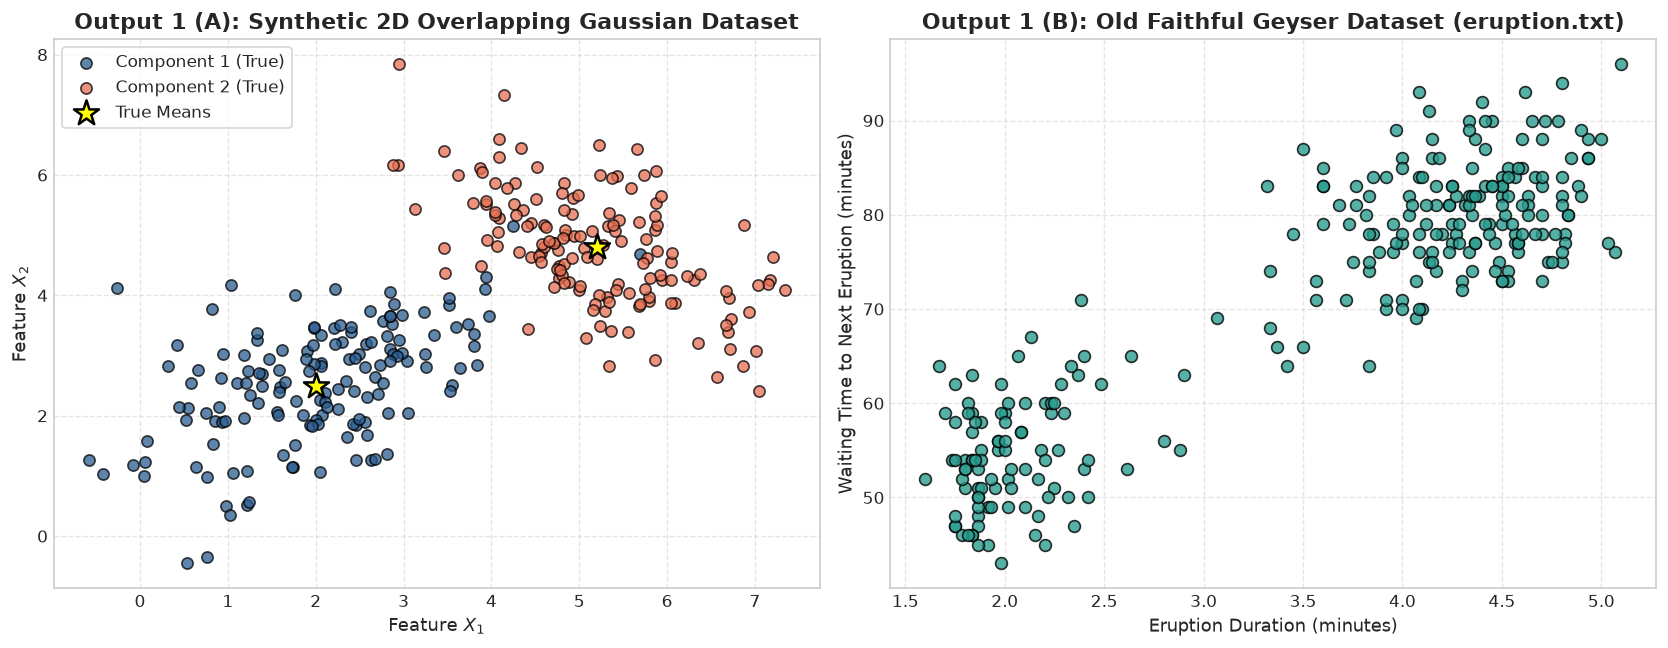

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

axes[0].scatter(X_syn[y_syn == 0, 0], X_syn[y_syn == 0, 1], c="#2b5c8f", alpha=0.75, edgecolors="k", s=45, label="Component 1 (True)")
axes[0].scatter(X_syn[y_syn == 1, 0], X_syn[y_syn == 1, 1], c="#e76f51", alpha=0.75, edgecolors="k", s=45, label="Component 2 (True)")
axes[0].scatter([true_mu1[0], true_mu2[0]], [true_mu1[1], true_mu2[1]], c="yellow", marker="*", s=250, edgecolors="black", linewidth=1.5, label="True Means", zorder=5)
axes[0].set_title("Output 1 (A): Synthetic 2D Overlapping Gaussian Dataset", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Feature $X_1$", fontsize=11)
axes[0].set_ylabel("Feature $X_2$", fontsize=11)
axes[0].legend(loc="upper left", frameon=True)
axes[0].grid(True, linestyle="--", alpha=0.5)

axes[1].scatter(df_erup["eruptions"], df_erup["waiting"], c="#2a9d8f", alpha=0.8, edgecolors="k", s=50)
axes[1].set_title("Output 1 (B): Old Faithful Geyser Dataset (eruption.txt)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Eruption Duration (minutes)", fontsize=11)
axes[1].set_ylabel("Waiting Time to Next Eruption (minutes)", fontsize=11)
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


In [ ]:
def draw_covariance_ellipse(position, covariance, ax=None, n_std=2.0, **kwargs):
    ax = ax or plt.gca()
    vals, vecs = np.linalg.eigh(covariance)
    order = vals.argsort()[::-1]
    vals, vecs = vals[order], vecs[:, order]
    theta = np.degrees(np.arctan2(*vecs[:, 0][::-1]))
    width, height = 2 * n_std * np.sqrt(np.maximum(vals, 1e-8))
    ellipse = Ellipse(xy=position, width=width, height=height, angle=theta, **kwargs)
    ax.add_patch(ellipse)
    return ellipse


class GaussianMixtureModelEM:
    def __init__(self, n_components=2, init_type='kmeans', max_iter=100, tol=1e-4, reg_covar=1e-6, random_state=42):
        self.K = n_components
        self.init_type = init_type.lower()
        self.max_iter = max_iter
        self.tol = tol
        self.reg_covar = reg_covar
        self.random_state = random_state
        
        self.weights = None        # Shape: (K,)
        self.means = None          # Shape: (K, D)
        self.covariances = None    # Shape: (K, D, D)
        self.log_likelihood_history = []
        self.n_iter = 0
        self.execution_time = 0.0

    def _init_parameters(self, X):
        N, D = X.shape
        rng = np.random.RandomState(self.random_state)
        self.covariances = np.zeros((self.K, D, D))
        
        if self.init_type == 'kmeans':
            km = KMeans(n_clusters=self.K, init='k-means++', random_state=self.random_state, n_init=10).fit(X)
            self.means = km.cluster_centers_.copy()
            labels = km.labels_
            self.weights = np.zeros(self.K)
            for k in range(self.K):
                cluster_pts = X[labels == k]
                if len(cluster_pts) > D:
                    self.covariances[k] = np.cov(cluster_pts, rowvar=False) + self.reg_covar * np.eye(D)
                else:
                    self.covariances[k] = np.cov(X, rowvar=False) + self.reg_covar * np.eye(D)
                self.weights[k] = max(len(cluster_pts), 1) / N
            self.weights /= np.sum(self.weights)
            
        elif self.init_type == 'random':
            indices = rng.choice(N, self.K, replace=False)
            self.means = X[indices].copy()
            self.weights = np.ones(self.K) / self.K
            sample_cov = np.cov(X, rowvar=False) + self.reg_covar * np.eye(D)
            for k in range(self.K):
                self.covariances[k] = sample_cov.copy()
        else:
            raise ValueError(f"Unknown initialization strategy: {self.init_type}. Use 'random' or 'kmeans'.")

    def _e_step(self, X):

        N, D = X.shape
        responsibilities = np.zeros((N, self.K))
        for k in range(self.K):
            cov = self.covariances[k] + self.reg_covar * np.eye(D)
            mvn = multivariate_normal(mean=self.means[k], cov=cov, allow_singular=True)
            responsibilities[:, k] = self.weights[k] * mvn.pdf(X)
            
        total_p = np.sum(responsibilities, axis=1, keepdims=True)
        log_likelihood = np.sum(np.log(np.maximum(total_p, 1e-12)))
        responsibilities /= np.maximum(total_p, 1e-12)
        return responsibilities, log_likelihood

    def _m_step(self, X, responsibilities):
        N, D = X.shape
        Nk = np.sum(responsibilities, axis=0)  # Shape: (K,)
        
        self.weights = Nk / N
        
        for k in range(self.K):
            if Nk[k] > 1e-8:
                self.means[k] = np.sum(responsibilities[:, k:k+1] * X, axis=0) / Nk[k]
                diff = X - self.means[k]
                self.covariances[k] = ((responsibilities[:, k:k+1] * diff).T @ diff) / Nk[k] + self.reg_covar * np.eye(D)
            else:
                self.covariances[k] = np.eye(D) * self.reg_covar

    def fit(self, X):
        start_time = time.time()
        self._init_parameters(X)
        self.log_likelihood_history = []
        
        for it in range(self.max_iter):
            responsibilities, current_ll = self._e_step(X)
            self.log_likelihood_history.append(current_ll)
            
            if it > 0 and abs(self.log_likelihood_history[-1] - self.log_likelihood_history[-2]) < self.tol:
                break
                
            self._m_step(X, responsibilities)
            
        self.n_iter = len(self.log_likelihood_history)
        self.execution_time = time.time() - start_time
        return self

    def predict_proba(self, X):
        resp, _ = self._e_step(X)
        return resp

    def predict(self, X):
        return np.argmax(self.predict_proba(X), axis=1)

    def score(self, X):
        _, ll = self._e_step(X)
        return ll

    def bic(self, X):
        N, D = X.shape
        n_params = (self.K - 1) + self.K * D + self.K * D * (D + 1) // 2
        return -2 * self.score(X) + n_params * np.log(N)

    def aic(self, X):
        N, D = X.shape
        n_params = (self.K - 1) + self.K * D + self.K * D * (D + 1) // 2
        return -2 * self.score(X) + 2 * n_params

print("GaussianMixtureModelEM class successfully implemented!")


GaussianMixtureModelEM class successfully implemented!


In [ ]:
gmm_syn_random = GaussianMixtureModelEM(n_components=2, init_type='random', random_state=42).fit(X_syn)
gmm_syn_kmeans = GaussianMixtureModelEM(n_components=2, init_type='kmeans', random_state=42).fit(X_syn)

gmm_erup_random = GaussianMixtureModelEM(n_components=2, init_type='random', random_state=42).fit(X_erup_scaled)
gmm_erup_kmeans = GaussianMixtureModelEM(n_components=2, init_type='kmeans', random_state=42).fit(X_erup_scaled)

preds_syn_rnd = gmm_syn_random.predict(X_syn)
preds_syn_km = gmm_syn_kmeans.predict(X_syn)

preds_erup_rnd = gmm_erup_random.predict(X_erup_scaled)
preds_erup_km = gmm_erup_kmeans.predict(X_erup_scaled)

exp1_results = [
    {
        "Dataset": "Synthetic 2D",
        "Initialization": "Random",
        "Log-Likelihood": f"{gmm_syn_random.log_likelihood_history[-1]:.2f}",
        "Iterations": gmm_syn_random.n_iter,
        "Execution Time (s)": f"{gmm_syn_random.execution_time:.4f}",
        "Silhouette Score": f"{silhouette_score(X_syn, preds_syn_rnd):.4f}",
        "ARI": f"{adjusted_rand_score(y_syn, preds_syn_rnd):.4f}",
        "NMI": f"{normalized_mutual_info_score(y_syn, preds_syn_rnd):.4f}"
    },
    {
        "Dataset": "Synthetic 2D",
        "Initialization": "K-Means",
        "Log-Likelihood": f"{gmm_syn_kmeans.log_likelihood_history[-1]:.2f}",
        "Iterations": gmm_syn_kmeans.n_iter,
        "Execution Time (s)": f"{gmm_syn_kmeans.execution_time:.4f}",
        "Silhouette Score": f"{silhouette_score(X_syn, preds_syn_km):.4f}",
        "ARI": f"{adjusted_rand_score(y_syn, preds_syn_km):.4f}",
        "NMI": f"{normalized_mutual_info_score(y_syn, preds_syn_km):.4f}"
    },
    {
        "Dataset": "Old Faithful",
        "Initialization": "Random",
        "Log-Likelihood": f"{gmm_erup_random.log_likelihood_history[-1]:.2f}",
        "Iterations": gmm_erup_random.n_iter,
        "Execution Time (s)": f"{gmm_erup_random.execution_time:.4f}",
        "Silhouette Score": f"{silhouette_score(X_erup_scaled, preds_erup_rnd):.4f}",
        "ARI": "N/A (Unlabeled)",
        "NMI": "N/A (Unlabeled)"
    },
    {
        "Dataset": "Old Faithful",
        "Initialization": "K-Means",
        "Log-Likelihood": f"{gmm_erup_kmeans.log_likelihood_history[-1]:.2f}",
        "Iterations": gmm_erup_kmeans.n_iter,
        "Execution Time (s)": f"{gmm_erup_kmeans.execution_time:.4f}",
        "Silhouette Score": f"{silhouette_score(X_erup_scaled, preds_erup_km):.4f}",
        "ARI": "N/A (Unlabeled)",
        "NMI": "N/A (Unlabeled)"
    }
]

df_exp1 = pd.DataFrame(exp1_results)
print("Experiment 1: Initialization Strategy Performance Comparison Table:")
display(df_exp1)


,Dataset,Initialization,Log-Likelihood,Iterations,Execution Time (s),Silhouette Score,ARI,NMI
0,Synthetic 2D,Random,-978.92,39,0.0157,0.5765,0.9342,0.8782
1,Synthetic 2D,K-Means,-978.92,10,0.1373,0.5765,0.9342,0.8782
2,Old Faithful,Random,-385.46,11,0.0041,0.7460,N/A (Unlabeled),N/A (Unlabeled)
3,Old Faithful,K-Means,-385.46,6,0.0185,0.7460,N/A (Unlabeled),N/A (Unlabeled)


Experiment 1: Initialization Strategy Performance Comparison Table:


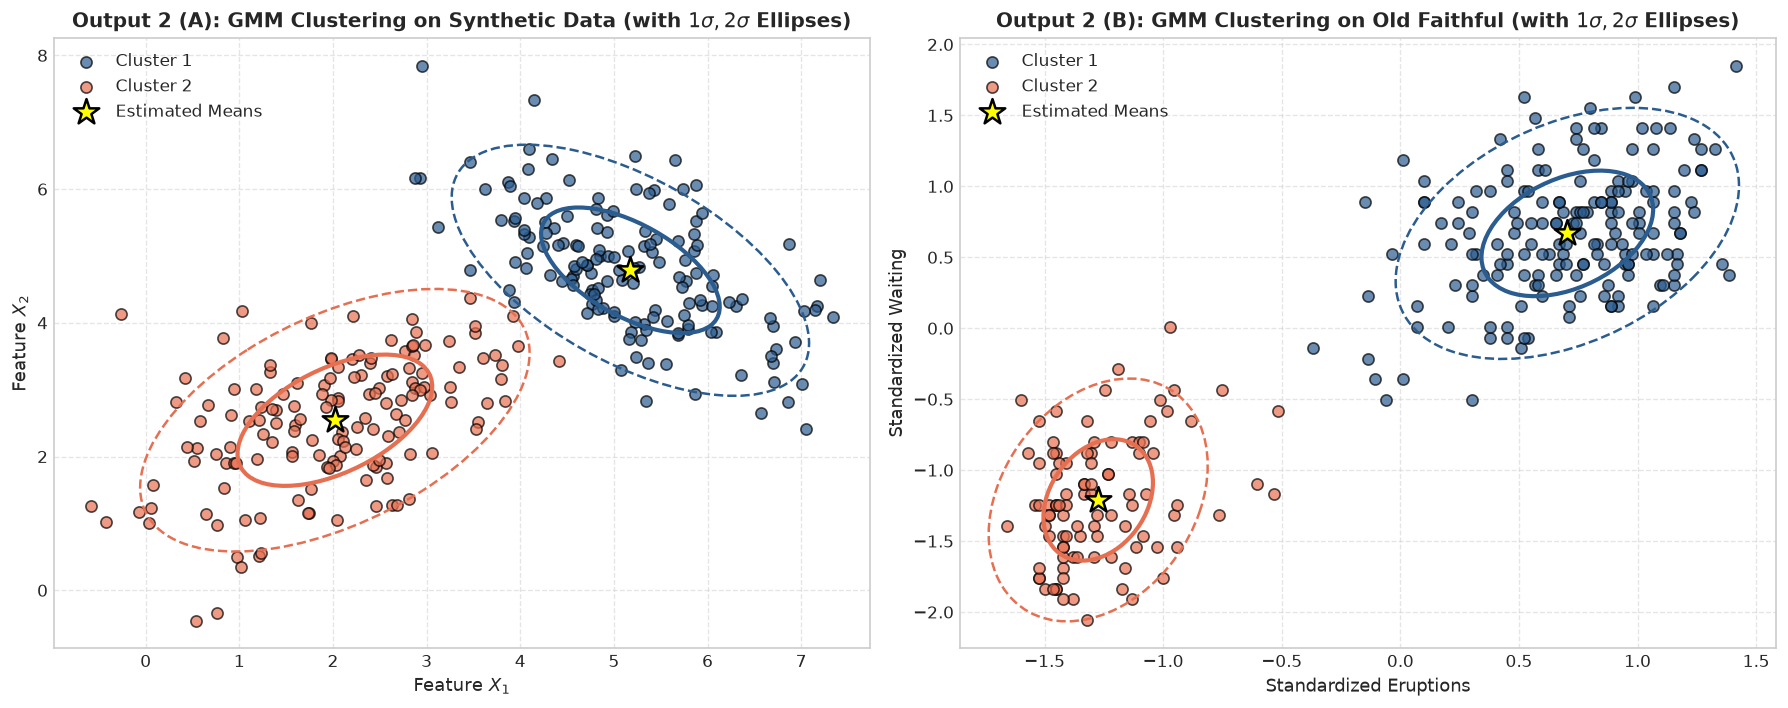

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

colors = ["#2b5c8f", "#e76f51"]

for k in range(gmm_syn_kmeans.K):
    cluster_data = X_syn[preds_syn_km == k]
    axes[0].scatter(cluster_data[:, 0], cluster_data[:, 1], c=colors[k], alpha=0.7, edgecolors="k", s=45, label=f"Cluster {k+1}")
    # Covariance Ellipses: 1-std and 2-std
    draw_covariance_ellipse(gmm_syn_kmeans.means[k], gmm_syn_kmeans.covariances[k], ax=axes[0], n_std=1.0, 
                            edgecolor=colors[k], facecolor="none", linewidth=2.5, linestyle="-")
    draw_covariance_ellipse(gmm_syn_kmeans.means[k], gmm_syn_kmeans.covariances[k], ax=axes[0], n_std=2.0, 
                            edgecolor=colors[k], facecolor="none", linewidth=1.5, linestyle="--")

axes[0].scatter(gmm_syn_kmeans.means[:, 0], gmm_syn_kmeans.means[:, 1], c="yellow", marker="*", s=260, edgecolors="k", linewidth=1.5, label="Estimated Means", zorder=6)
axes[0].set_title("Output 2 (A): GMM Clustering on Synthetic Data (with $1\sigma, 2\sigma$ Ellipses)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Feature $X_1$", fontsize=11)
axes[0].set_ylabel("Feature $X_2$", fontsize=11)
axes[0].legend(loc="upper left")
axes[0].grid(True, linestyle="--", alpha=0.5)

for k in range(gmm_erup_kmeans.K):
    cluster_data = X_erup_scaled[preds_erup_km == k]
    axes[1].scatter(cluster_data[:, 0], cluster_data[:, 1], c=colors[k], alpha=0.7, edgecolors="k", s=45, label=f"Cluster {k+1}")
    draw_covariance_ellipse(gmm_erup_kmeans.means[k], gmm_erup_kmeans.covariances[k], ax=axes[1], n_std=1.0, 
                            edgecolor=colors[k], facecolor="none", linewidth=2.5, linestyle="-")
    draw_covariance_ellipse(gmm_erup_kmeans.means[k], gmm_erup_kmeans.covariances[k], ax=axes[1], n_std=2.0, 
                            edgecolor=colors[k], facecolor="none", linewidth=1.5, linestyle="--")

axes[1].scatter(gmm_erup_kmeans.means[:, 0], gmm_erup_kmeans.means[:, 1], c="yellow", marker="*", s=260, edgecolors="k", linewidth=1.5, label="Estimated Means", zorder=6)
axes[1].set_title("Output 2 (B): GMM Clustering on Old Faithful (with $1\sigma, 2\sigma$ Ellipses)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Standardized Eruptions", fontsize=11)
axes[1].set_ylabel("Standardized Waiting", fontsize=11)
axes[1].legend(loc="upper left")
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


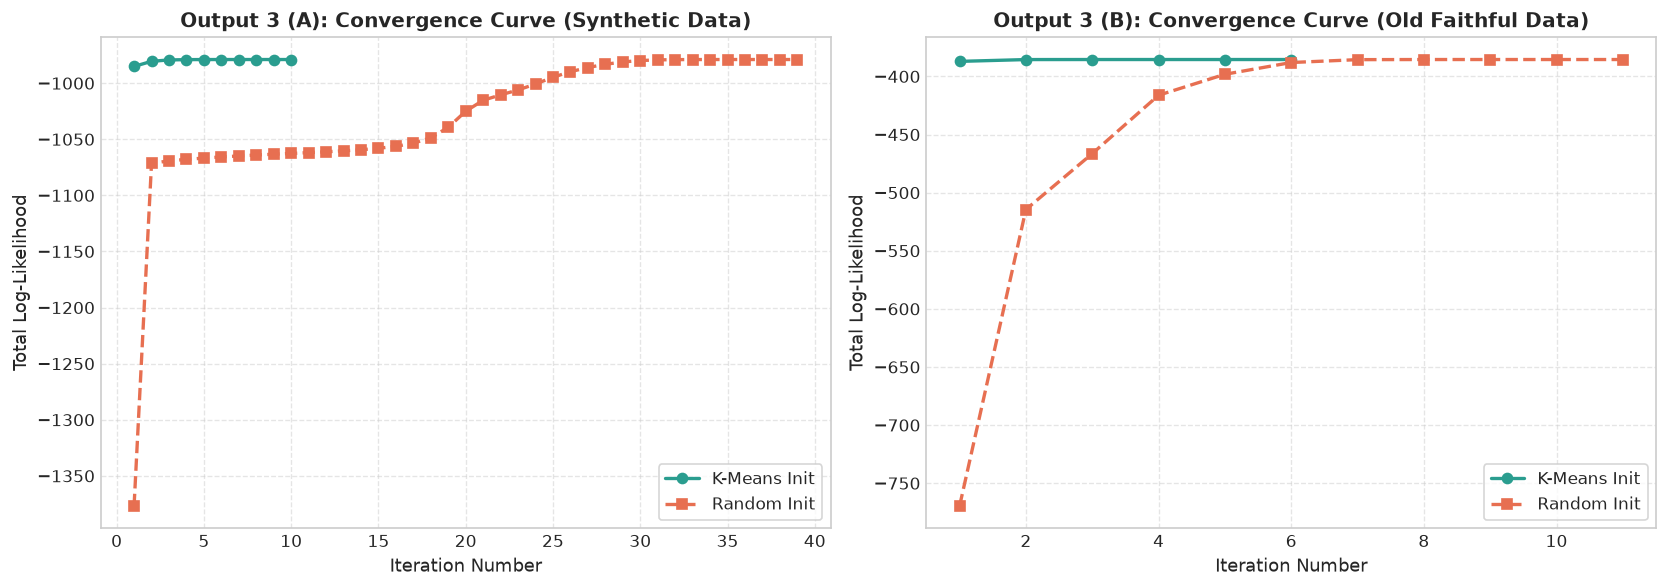

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(range(1, gmm_syn_kmeans.n_iter + 1), gmm_syn_kmeans.log_likelihood_history, 
             marker="o", markersize=6, linewidth=2, color="#2a9d8f", label="K-Means Init")
axes[0].plot(range(1, gmm_syn_random.n_iter + 1), gmm_syn_random.log_likelihood_history, 
             marker="s", markersize=6, linewidth=2, linestyle="--", color="#e76f51", label="Random Init")
axes[0].set_title("Output 3 (A): Convergence Curve (Synthetic Data)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Iteration Number", fontsize=11)
axes[0].set_ylabel("Total Log-Likelihood", fontsize=11)
axes[0].legend(loc="lower right", frameon=True)
axes[0].grid(True, linestyle="--", alpha=0.5)

axes[1].plot(range(1, gmm_erup_kmeans.n_iter + 1), gmm_erup_kmeans.log_likelihood_history, 
             marker="o", markersize=6, linewidth=2, color="#2a9d8f", label="K-Means Init")
axes[1].plot(range(1, gmm_erup_random.n_iter + 1), gmm_erup_random.log_likelihood_history, 
             marker="s", markersize=6, linewidth=2, linestyle="--", color="#e76f51", label="Random Init")
axes[1].set_title("Output 3 (B): Convergence Curve (Old Faithful Data)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Iteration Number", fontsize=11)
axes[1].set_ylabel("Total Log-Likelihood", fontsize=11)
axes[1].legend(loc="lower right", frameon=True)
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


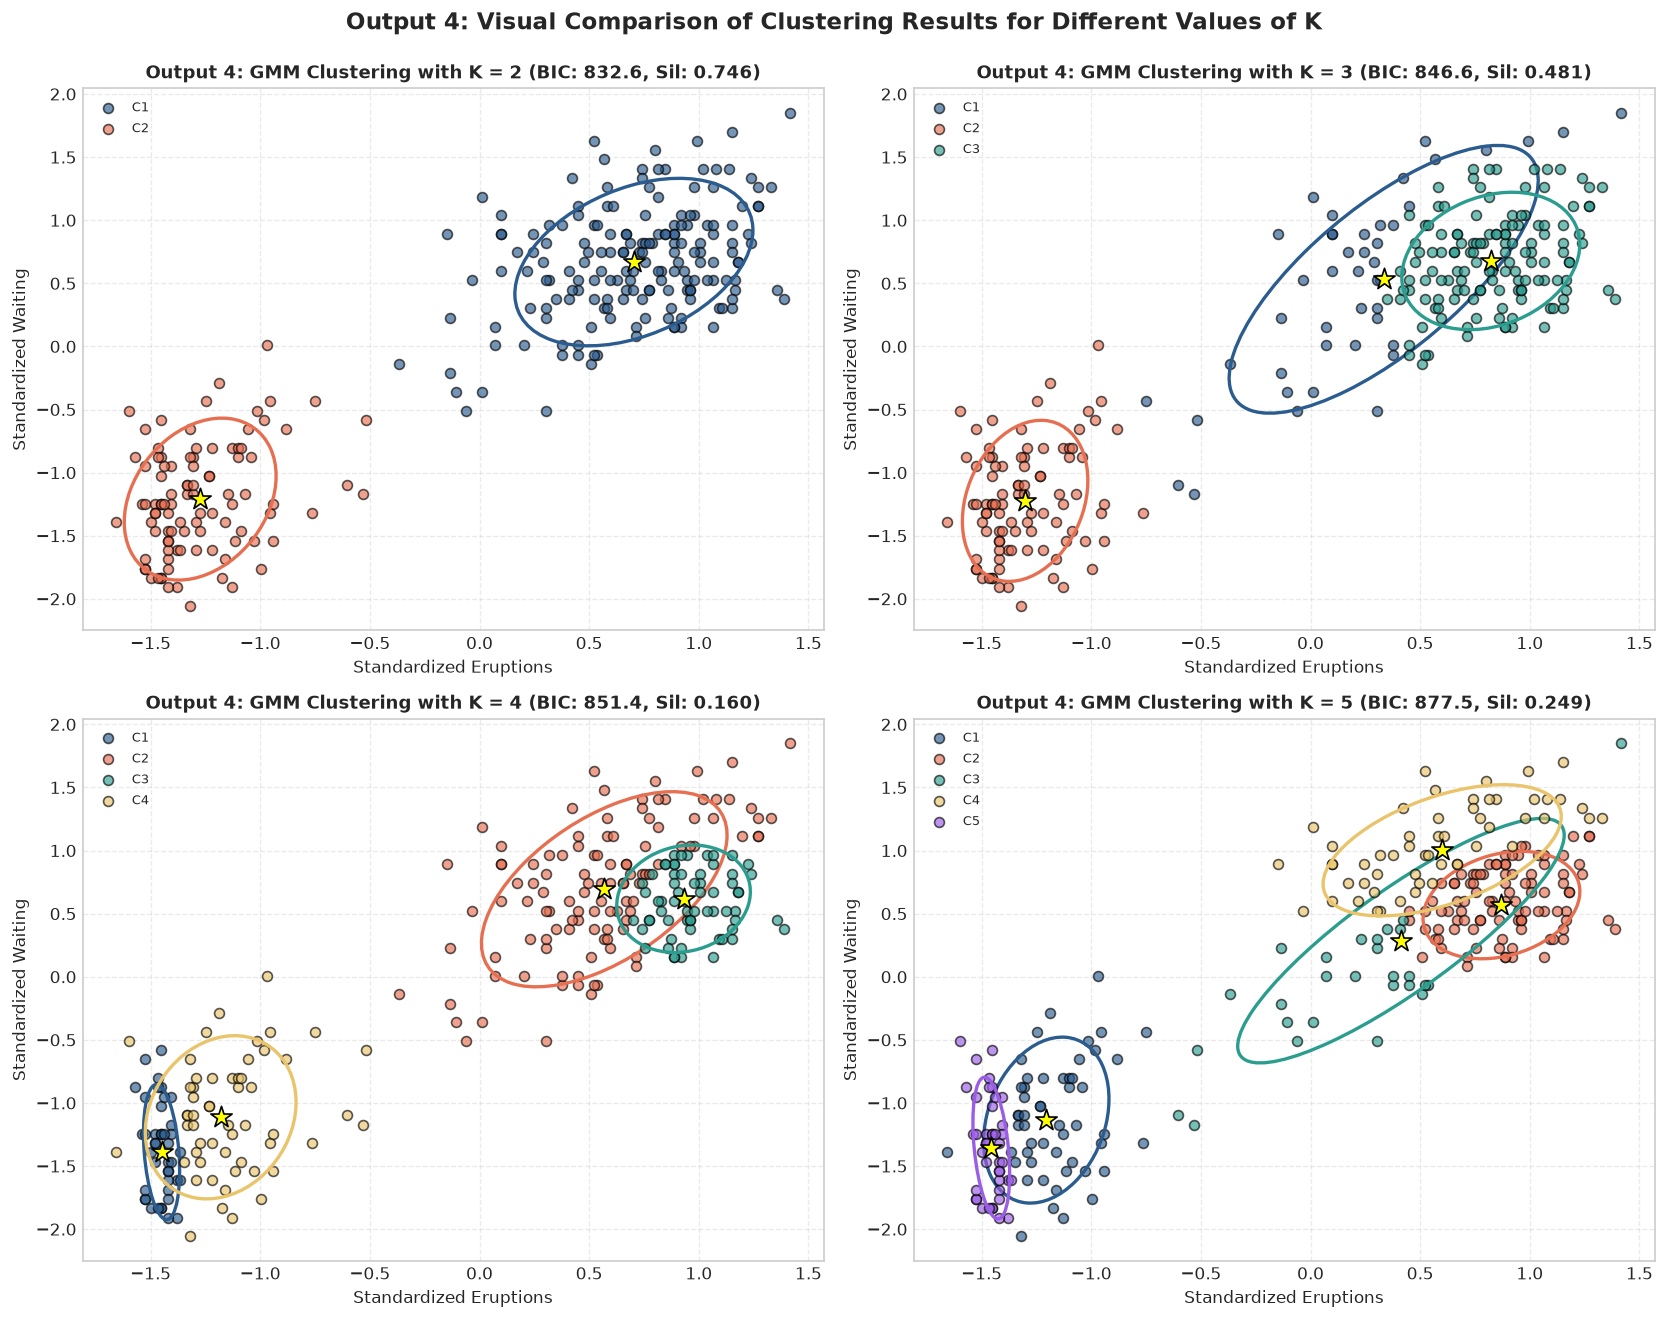

,K (Components),Log-Likelihood,AIC,BIC,Silhouette Score,Iterations,Time (s)
0,2,-385.46,792.92,832.59,0.7460,6,0.0120
1,3,-375.65,785.29,846.59,0.4808,100,0.0474
2,4,-361.26,768.52,851.45,0.1602,100,0.0593
3,5,-357.47,772.94,877.51,0.2487,100,0.0706


Experiment 2: Model Comparison across Component Counts K = 2, 3, 4, 5:


In [ ]:
K_values = [2, 3, 4, 5]
models_k = {}
metrics_k = []

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
axes = axes.flatten()
cmap_list = ["#2b5c8f", "#e76f51", "#2a9d8f", "#e9c46a", "#9b5de5"]

for idx, k in enumerate(K_values):
    gmm_k = GaussianMixtureModelEM(n_components=k, init_type='kmeans', random_state=42).fit(X_erup_scaled)
    models_k[k] = gmm_k
    preds = gmm_k.predict(X_erup_scaled)
    
    ll = gmm_k.log_likelihood_history[-1]
    aic = gmm_k.aic(X_erup_scaled)
    bic = gmm_k.bic(X_erup_scaled)
    sil = silhouette_score(X_erup_scaled, preds)
    
    metrics_k.append({
        "K (Components)": k,
        "Log-Likelihood": f"{ll:.2f}",
        "AIC": f"{aic:.2f}",
        "BIC": f"{bic:.2f}",
        "Silhouette Score": f"{sil:.4f}",
        "Iterations": gmm_k.n_iter,
        "Time (s)": f"{gmm_k.execution_time:.4f}"
    })
    
    ax = axes[idx]
    for comp in range(k):
        pts = X_erup_scaled[preds == comp]
        if len(pts) > 0:
            ax.scatter(pts[:, 0], pts[:, 1], c=cmap_list[comp % len(cmap_list)], 
                       alpha=0.65, edgecolors="k", s=35, label=f"C{comp+1}")
        draw_covariance_ellipse(gmm_k.means[comp], gmm_k.covariances[comp], ax=ax, n_std=1.5,
                                edgecolor=cmap_list[comp % len(cmap_list)], facecolor="none", linewidth=2)
    ax.scatter(gmm_k.means[:, 0], gmm_k.means[:, 1], c="yellow", marker="*", s=180, edgecolors="k", zorder=5)
    ax.set_title(f"Output 4: GMM Clustering with K = {k} (BIC: {bic:.1f}, Sil: {sil:.3f})", fontsize=11, fontweight="bold")
    ax.set_xlabel("Standardized Eruptions")
    ax.set_ylabel("Standardized Waiting")
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.legend(loc="upper left", fontsize=8)

plt.suptitle("Output 4: Visual Comparison of Clustering Results for Different Values of K", fontsize=14, fontweight="bold", y=0.995)
plt.tight_layout()
plt.show()

df_metrics_k = pd.DataFrame(metrics_k)
print("Experiment 2: Model Comparison across Component Counts K = 2, 3, 4, 5:")
display(df_metrics_k)


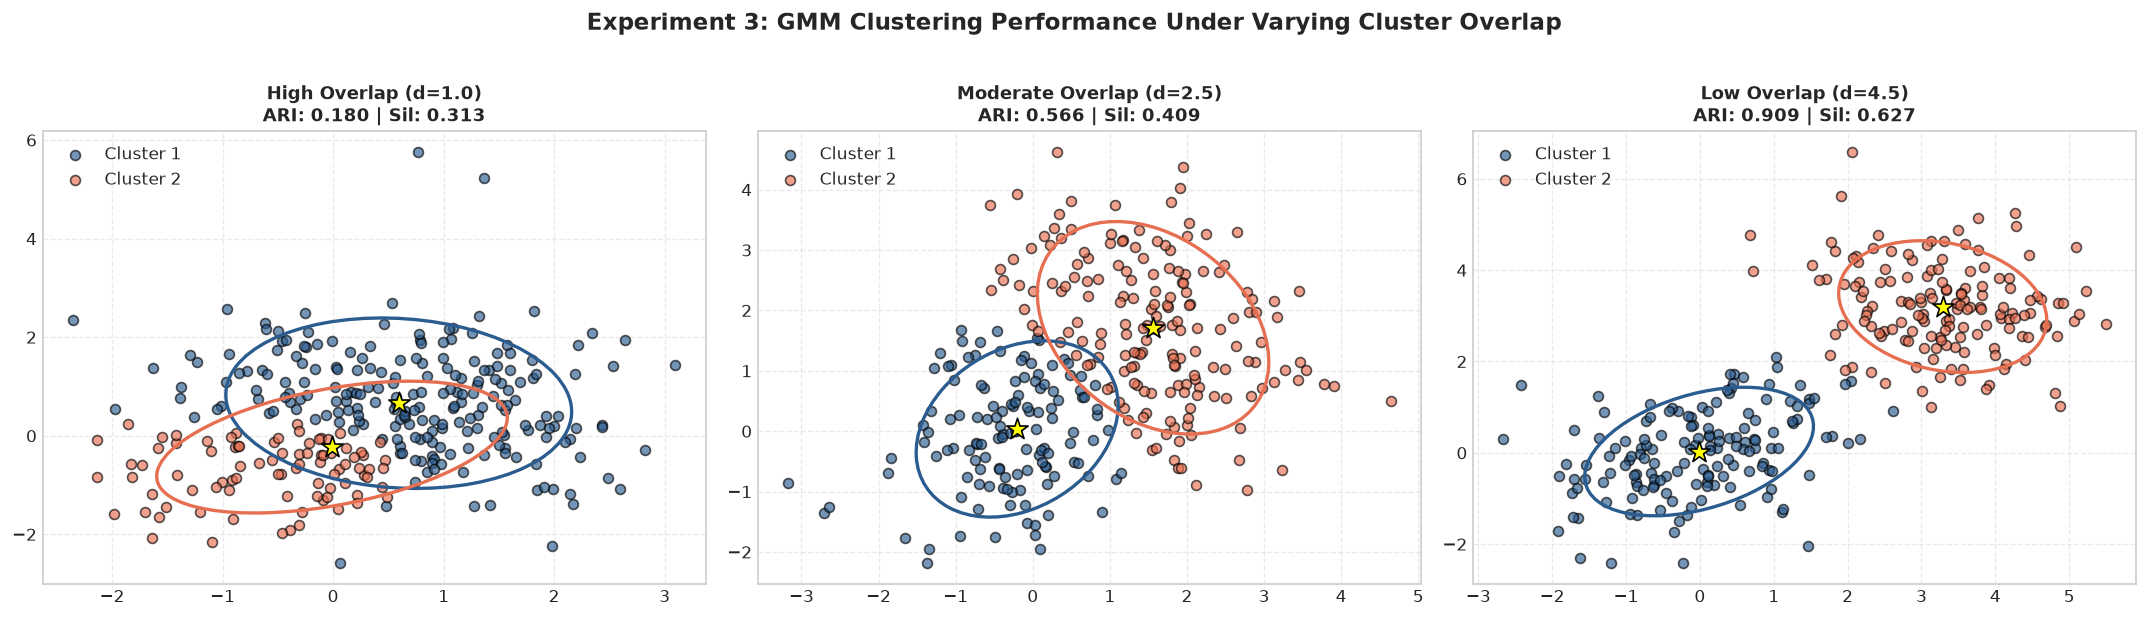

,Degree of Overlap,Mean Separation (d),ARI,NMI,Silhouette Score,Final Log-Likelihood,Iterations
0,High Overlap (d=1.0),1.0,0.1798,0.1880,0.3129,-908.78,100
1,Moderate Overlap (d=2.5),2.5,0.5661,0.4901,0.4093,-981.08,27
2,Low Overlap (d=4.5),4.5,0.9085,0.8406,0.6273,-1013.87,11


Experiment 3: Cluster Overlap Performance Table:


In [ ]:
separations = [1.0, 2.5, 4.5]
overlap_labels = ["High Overlap (d=1.0)", "Moderate Overlap (d=2.5)", "Low Overlap (d=4.5)"]
overlap_results = []

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, (sep, o_label) in enumerate(zip(separations, overlap_labels)):
    np.random.seed(100 + i)
    m1 = np.array([0.0, 0.0])
    m2 = np.array([sep / np.sqrt(2), sep / np.sqrt(2)])
    c1 = np.array([[1.0, 0.3], [0.3, 0.8]])
    c2 = np.array([[0.9, -0.2], [-0.2, 1.1]])
    
    pts1 = np.random.multivariate_normal(m1, c1, 150)
    pts2 = np.random.multivariate_normal(m2, c2, 150)
    X_over = np.vstack([pts1, pts2])
    y_over = np.array([0]*150 + [1]*150)
    
    gmm_over = GaussianMixtureModelEM(n_components=2, init_type='kmeans', random_state=42).fit(X_over)
    preds_over = gmm_over.predict(X_over)
    
    ari = adjusted_rand_score(y_over, preds_over)
    nmi = normalized_mutual_info_score(y_over, preds_over)
    sil = silhouette_score(X_over, preds_over)
    
    overlap_results.append({
        "Degree of Overlap": o_label,
        "Mean Separation (d)": sep,
        "ARI": f"{ari:.4f}",
        "NMI": f"{nmi:.4f}",
        "Silhouette Score": f"{sil:.4f}",
        "Final Log-Likelihood": f"{gmm_over.log_likelihood_history[-1]:.2f}",
        "Iterations": gmm_over.n_iter
    })
    
    ax = axes[i]
    ax.scatter(X_over[preds_over == 0, 0], X_over[preds_over == 0, 1], c="#2b5c8f", alpha=0.65, edgecolors="k", s=35, label="Cluster 1")
    ax.scatter(X_over[preds_over == 1, 0], X_over[preds_over == 1, 1], c="#e76f51", alpha=0.65, edgecolors="k", s=35, label="Cluster 2")
    draw_covariance_ellipse(gmm_over.means[0], gmm_over.covariances[0], ax=ax, n_std=1.5, edgecolor="#2b5c8f", facecolor="none", linewidth=2)
    draw_covariance_ellipse(gmm_over.means[1], gmm_over.covariances[1], ax=ax, n_std=1.5, edgecolor="#e76f51", facecolor="none", linewidth=2)
    ax.scatter(gmm_over.means[:, 0], gmm_over.means[:, 1], c="yellow", marker="*", s=180, edgecolors="k", zorder=5)
    ax.set_title(f"{o_label}\nARI: {ari:.3f} | Sil: {sil:.3f}", fontsize=11, fontweight="bold")
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.legend(loc="upper left")

plt.suptitle("Experiment 3: GMM Clustering Performance Under Varying Cluster Overlap", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

df_overlap = pd.DataFrame(overlap_results)
print("Experiment 3: Cluster Overlap Performance Table:")
display(df_overlap)


,Initialization,Log-Likelihood (Mean ± Std),Log-Likelihood Range,Iterations (Mean ± Std),ARI (Mean ± Std)
0,Random Initialization (10 runs),-978.92 ± 0.00,"[-978.92, -978.92]",25.4 ± 9.5,0.9342 ± 0.0000
1,K-Means Initialization (10 runs),-978.92 ± 0.00,"[-978.92, -978.92]",10.0 ± 0.0,0.9342 ± 0.0000


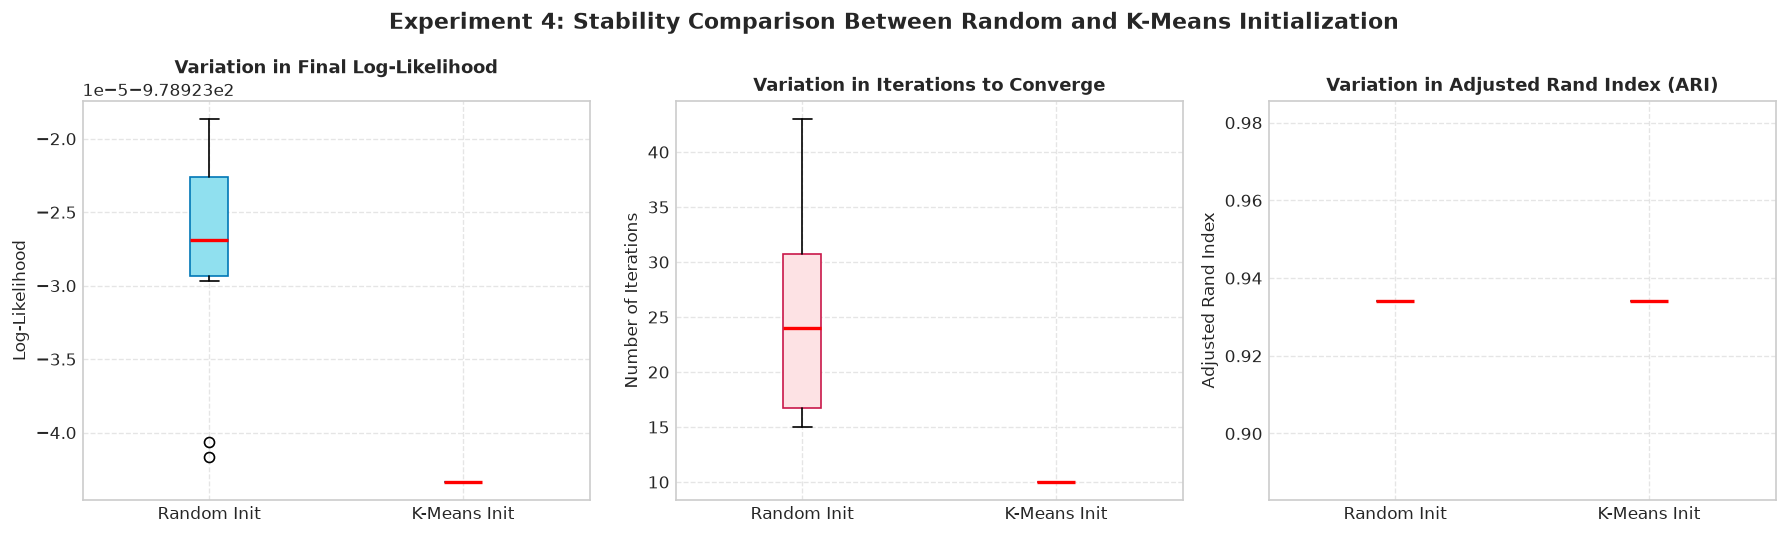

Experiment 4: Initialization Variability Summary Table (10 Runs):


In [ ]:
n_runs = 10
seeds = [10, 23, 42, 57, 88, 101, 123, 204, 314, 500]

rand_lls, rand_iters, rand_aris = [], [], []
km_lls, km_iters, km_aris = [], [], []

for s in seeds:
    g_rnd = GaussianMixtureModelEM(n_components=2, init_type='random', random_state=s).fit(X_syn)
    rand_lls.append(g_rnd.log_likelihood_history[-1])
    rand_iters.append(g_rnd.n_iter)
    rand_aris.append(adjusted_rand_score(y_syn, g_rnd.predict(X_syn)))
    
    g_km = GaussianMixtureModelEM(n_components=2, init_type='kmeans', random_state=s).fit(X_syn)
    km_lls.append(g_km.log_likelihood_history[-1])
    km_iters.append(g_km.n_iter)
    km_aris.append(adjusted_rand_score(y_syn, g_km.predict(X_syn)))

variability_summary = [
    {
        "Initialization": "Random Initialization (10 runs)",
        "Log-Likelihood (Mean ± Std)": f"{np.mean(rand_lls):.2f} ± {np.std(rand_lls):.2f}",
        "Log-Likelihood Range": f"[{np.min(rand_lls):.2f}, {np.max(rand_lls):.2f}]",
        "Iterations (Mean ± Std)": f"{np.mean(rand_iters):.1f} ± {np.std(rand_iters):.1f}",
        "ARI (Mean ± Std)": f"{np.mean(rand_aris):.4f} ± {np.std(rand_aris):.4f}"
    },
    {
        "Initialization": "K-Means Initialization (10 runs)",
        "Log-Likelihood (Mean ± Std)": f"{np.mean(km_lls):.2f} ± {np.std(km_lls):.2f}",
        "Log-Likelihood Range": f"[{np.min(km_lls):.2f}, {np.max(km_lls):.2f}]",
        "Iterations (Mean ± Std)": f"{np.mean(km_iters):.1f} ± {np.std(km_iters):.1f}",
        "ARI (Mean ± Std)": f"{np.mean(km_aris):.4f} ± {np.std(km_aris):.4f}"
    }
]

df_variability = pd.DataFrame(variability_summary)
print("Experiment 4: Initialization Variability Summary Table (10 Runs):")
display(df_variability)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

axes[0].boxplot([rand_lls, km_lls], tick_labels=["Random Init", "K-Means Init"], patch_artist=True,
                boxprops=dict(facecolor="#90e0ef", color="#0077b6"), medianprops=dict(color="red", linewidth=2))
axes[0].set_title("Variation in Final Log-Likelihood", fontsize=11, fontweight="bold")
axes[0].set_ylabel("Log-Likelihood")
axes[0].grid(True, linestyle="--", alpha=0.5)

axes[1].boxplot([rand_iters, km_iters], tick_labels=["Random Init", "K-Means Init"], patch_artist=True,
                boxprops=dict(facecolor="#fde2e4", color="#c9184a"), medianprops=dict(color="red", linewidth=2))
axes[1].set_title("Variation in Iterations to Converge", fontsize=11, fontweight="bold")
axes[1].set_ylabel("Number of Iterations")
axes[1].grid(True, linestyle="--", alpha=0.5)

axes[2].boxplot([rand_aris, km_aris], tick_labels=["Random Init", "K-Means Init"], patch_artist=True,
                boxprops=dict(facecolor="#d8f3dc", color="#2d6a4f"), medianprops=dict(color="red", linewidth=2))
axes[2].set_title("Variation in Adjusted Rand Index (ARI)", fontsize=11, fontweight="bold")
axes[2].set_ylabel("Adjusted Rand Index")
axes[2].grid(True, linestyle="--", alpha=0.5)

plt.suptitle("Experiment 4: Stability Comparison Between Random and K-Means Initialization", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()
